<a href="https://colab.research.google.com/github/udlbook/udlbook/blob/main/Notebooks/Chap10/10_2_Convolution_for_MNIST_1D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Notebook 10.2: Convolution for MNIST-1D**

This notebook investigates a 1D convolutional network for MNIST-1D as in figure 10.7 and 10.8a.

Work through the cells below, running each cell in turn. In various places you will see the words "TODO". Follow the instructions at these places and make predictions about what is going to happen or write code to complete the functions.

Contact me at udlbookmail@gmail.com if you find any mistakes or have any suggestions.



In [1]:
# Run this if you're in a Colab to install MNIST 1D repository
!pip install git+https://github.com/greydanus/mnist1d

  Cloning https://github.com/greydanus/mnist1d to /tmp/pip-req-build-hfwts9es
  Running command git clone --filter=blob:none --quiet https://github.com/greydanus/mnist1d /tmp/pip-req-build-hfwts9es
  Resolved https://github.com/greydanus/mnist1d to commit e2f536fa86442c13473b433d579e9852ec4d1c1d
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for mnist1d: filename=mnist1d-0.0.2.post23-py3-none-any.whl size=14666 sha256=034da928b83ede591a2839d6a49eab9885738d8eecfa04cadae859613ec84a02
  Stored in directory: /tmp/pip-ephem-wheel-cache-eygd1y2o/wheels/18/40/b6/29381fee9b4c80fdbc304d52bb065a7286bbcca5ca2b8737c0
Successfully built mnist1d
  Attempting uninstall: mnist1d
    Found existing installation: mnist1d 0.0.2.post16
    Uninstalling mnist1d-0.0.2.post16:
      Successfully uninstalled mnist1d-0.0.2.post16


In [2]:
import numpy as np
import os
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torch.optim.lr_scheduler import StepLR
import matplotlib.pyplot as plt
import mnist1d
import random

In [3]:
args = mnist1d.data.get_dataset_args()
data = mnist1d.data.get_dataset(args, path='./mnist1d_data.pkl', download=False, regenerate=False)

# The training and test input and outputs are in
# data['x'], data['y'], data['x_test'], and data['y_test']
print("Examples in training set: {}".format(len(data['y'])))
print("Examples in test set: {}".format(len(data['y_test'])))
print("Length of each example: {}".format(data['x'].shape[-1]))

Did or could not load data from ./mnist1d_data.pkl. Rebuilding dataset...
Examples in training set: 4000
Examples in test set: 1000
Length of each example: 40


In [4]:
# Load in the data
train_data_x = data['x'].transpose()
train_data_y = data['y']
val_data_x = data['x_test'].transpose()
val_data_y = data['y_test']
# Print out sizes
print("Train data: %d examples (columns), each of which has %d dimensions (rows)"%((train_data_x.shape[1],train_data_x.shape[0])))
print("Validation data: %d examples (columns), each of which has %d dimensions (rows)"%((val_data_x.shape[1],val_data_x.shape[0])))

Train data: 4000 examples (columns), each of which has 40 dimensions (rows)
Validation data: 1000 examples (columns), each of which has 40 dimensions (rows)


Define the network

In [11]:
# There are 40 input dimensions and 10 output dimensions for this data
# The inputs correspond to the 40 offsets in the MNIST1D template.
D_i = 40
# The outputs correspond to the 10 digits
D_o = 10


# TODO Create a model with the following layers


# NOTE THAT THE CONVOLUTIONAL LAYERS NEED TO TAKE THE NUMBER OF INPUT CHANNELS AS A PARAMETER
# AND NOT THE INPUT SIZE.

model = nn.Sequential(
    # Capa 1: recibe 1 canal, saca 15 canales. Reduce de 40 a 19 posiciones
    nn.Conv1d(in_channels=1, out_channels=15, kernel_size=3, stride=2, padding="valid"),
    nn.ReLU(),
    # Capa 2: recibe 15 canales, saca 15 canales. Reduce de 19 a 9 posiciones
    nn.Conv1d(in_channels=15, out_channels=15, kernel_size=3, stride=2, padding="valid"),
    nn.ReLU(),
    # Capa 3: recibe 15 canales, saca 15 canales. Reduce de 9 a 4 posiciones
    nn.Conv1d(in_channels=15, out_channels=15, kernel_size=3, stride=2, padding="valid"),
    nn.ReLU(),
    # Aplanamos: juntamos los 15 canales con sus 4 posiciones (15 x 4 = 60 números)
    nn.Flatten(),
    # Capa final: toma los 60 números y predice cuál de los 10 dígitos es
    nn.Linear(in_features=60, out_features=10)
)









In [12]:
# He initialization of weights
def weights_init(layer_in):
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)

Epoch     0, train loss 1.870260, train error 72.65,  val loss 1.874594, percent error 74.30
Epoch     1, train loss 1.529136, train error 60.95,  val loss 1.542808, percent error 64.00
Epoch     2, train loss 1.413832, train error 55.45,  val loss 1.426887, percent error 57.00
Epoch     3, train loss 1.251202, train error 49.35,  val loss 1.271493, percent error 50.80
Epoch     4, train loss 1.178180, train error 47.47,  val loss 1.202692, percent error 46.80
Epoch     5, train loss 1.049368, train error 41.53,  val loss 1.082382, percent error 44.50
Epoch     6, train loss 1.068215, train error 45.12,  val loss 1.121694, percent error 44.80
Epoch     7, train loss 0.987737, train error 38.88,  val loss 1.047695, percent error 40.40
Epoch     8, train loss 0.871334, train error 34.60,  val loss 0.936657, percent error 37.60
Epoch     9, train loss 0.810950, train error 32.75,  val loss 0.852709, percent error 36.20
Epoch    10, train loss 0.731100, train error 29.10,  val loss 0.78392

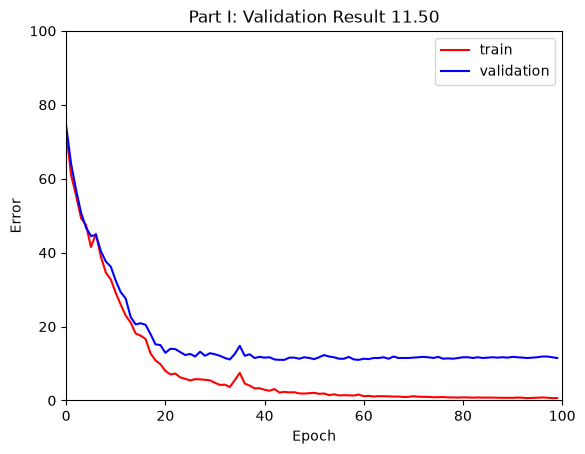

In [13]:
# choose cross entropy loss function (equation 5.24 in the loss notes)
loss_function = nn.CrossEntropyLoss()
# construct SGD optimizer and initialize learning rate and momentum
optimizer = torch.optim.SGD(model.parameters(), lr = 0.05, momentum=0.9)
# object that decreases learning rate by half every 20 epochs
scheduler = StepLR(optimizer, step_size=20, gamma=0.5)
# create 100 dummy data points and store in data loader class
x_train = torch.tensor(train_data_x.transpose().astype('float32'))
y_train = torch.tensor(train_data_y.astype('long')).long()
x_val= torch.tensor(val_data_x.transpose().astype('float32'))
y_val = torch.tensor(val_data_y.astype('long')).long()

# load the data into a class that creates the batches
data_loader = DataLoader(TensorDataset(x_train,y_train), batch_size=100, shuffle=True, worker_init_fn=np.random.seed(1))

# Initialize model weights
model.apply(weights_init)

# loop over the dataset n_epoch times
n_epoch = 100
# store the loss and the % correct at each epoch
losses_train = np.zeros((n_epoch))
errors_train = np.zeros((n_epoch))
losses_val = np.zeros((n_epoch))
errors_val = np.zeros((n_epoch))

for epoch in range(n_epoch):
  # loop over batches
  for i, data in enumerate(data_loader):
    # retrieve inputs and labels for this batch
    x_batch, y_batch = data
    # zero the parameter gradients
    optimizer.zero_grad()
    # forward pass -- calculate model output
    pred = model(x_batch[:,None,:])
    # compute the loss
    loss = loss_function(pred, y_batch)
    # backward pass
    loss.backward()
    # SGD update
    optimizer.step()

  # Run whole dataset to get statistics -- normally wouldn't do this
  pred_train = model(x_train[:,None,:])
  pred_val = model(x_val[:,None,:])
  _, predicted_train_class = torch.max(pred_train.data, 1)
  _, predicted_val_class = torch.max(pred_val.data, 1)
  errors_train[epoch] = 100 - 100 * (predicted_train_class == y_train).float().sum() / len(y_train)
  errors_val[epoch]= 100 - 100 * (predicted_val_class == y_val).float().sum() / len(y_val)
  losses_train[epoch] = loss_function(pred_train, y_train).item()
  losses_val[epoch]= loss_function(pred_val, y_val).item()
  print(f'Epoch {epoch:5d}, train loss {losses_train[epoch]:.6f}, train error {errors_train[epoch]:3.2f},  val loss {losses_val[epoch]:.6f}, percent error {errors_val[epoch]:3.2f}')

  # tell scheduler to consider updating learning rate
  scheduler.step()

# Plot the results
fig, ax = plt.subplots()
ax.plot(errors_train,'r-',label='train')
ax.plot(errors_val,'b-',label='validation')
ax.set_ylim(0,100); ax.set_xlim(0,n_epoch)
ax.set_xlabel('Epoch'); ax.set_ylabel('Error')
ax.set_title('Part I: Validation Result %3.2f'%(errors_val[-1]))
ax.legend()
plt.show()

### Resumen de lo visto

En este cuaderno pusimos en práctica las convoluciones para resolver una tarea real de reconocimiento de números en una dimensión. Comprobamos de primera mano la gran ventaja de usar capas convolucionales en lugar de capas densas comunes: al buscar patrones locales con filtros que se deslizan a lo largo de los datos, la red necesita muchísimos menos parámetros para entrenar y generaliza mucho mejor con datos nuevos.

A medida que los datos avanzan por las tres capas convolucionales, la señal se va resumiendo y achicando gracias a dar pasos de dos en dos, mientras que la cantidad de características observadas se multiplica al trabajar con quince canales a la vez. Al final, toda esa información resumida se junta en una pequeña lista de sesenta valores que una capa simple puede clasificar con gran precisión, logrando que el error de validación caiga drásticamente en comparación con una red tradicional.